# EuroSAT MS: quick EDA

The goal is a short, fast look at the training data before we build models. Each section ends with a
**→ so what** line: the decision it feeds into.

1. Class balance
2. What the patches look like
3. Value ranges and data quality
4. Spectral profile per class
5. Spectral indices (NDVI / NDWI / NDBI)
6. Which bands carry information (separability + redundancy)
7. Summary: channel choice for each model

Data: `dataset/EuroSAT_MS` via `sat.eurosat` (the first run builds a 2.9 GB cache in `dataset/cache/`, which takes ~2 min).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sat.bands import BANDS, BANDS_BY_WAVELENGTH, WAVELENGTHS_NM, BAND_DESCRIPTIONS, composite, normalized_difference
from sat.eurosat import CLASSES, load_split, load_cache

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "axes.titleweight": "bold"})
BLUE, BLUE_LIGHT, GRAY = "#2a78d6", "#b7d3f6", "#b9b8b2"

split = load_split()                 # one row per patch: path, class_name, label, split
arr = load_cache()                   # (27000, 13, 64, 64) uint16 memmap, same row order
labels = split["label"].to_numpy()
print(arr.shape, arr.dtype)
split.head()

(27000, 13, 64, 64) uint16


,path,class_name,label,split
0,AnnualCrop/AnnualCrop_1.tif,AnnualCrop,0,train
1,AnnualCrop/AnnualCrop_2.tif,AnnualCrop,0,test
2,AnnualCrop/AnnualCrop_3.tif,AnnualCrop,0,train
3,AnnualCrop/AnnualCrop_4.tif,AnnualCrop,0,test
4,AnnualCrop/AnnualCrop_5.tif,AnnualCrop,0,train


## 1. Class balance

In [2]:
counts = pd.crosstab(split["class_name"], split["split"])[["train", "val", "test"]]
counts["total"] = counts.sum(axis=1)
counts.loc["TOTAL"] = counts.sum()
counts

split,train,val,test,total
class_name,,,,
AnnualCrop,2100,450,450,3000
Forest,2100,450,450,3000
HerbaceousVegetation,2100,450,450,3000
Highway,1750,375,375,2500
Industrial,1750,375,375,2500
Pasture,1400,300,300,2000
PermanentCrop,1750,375,375,2500
Residential,2100,450,450,3000
River,1750,375,375,2500


**→ so what:** mild imbalance (2,000 Pasture vs 3,000 for the largest classes, ratio 1.5). No resampling
needed; report **macro-F1** next to accuracy so the small classes count equally.

## 2. What the patches look like

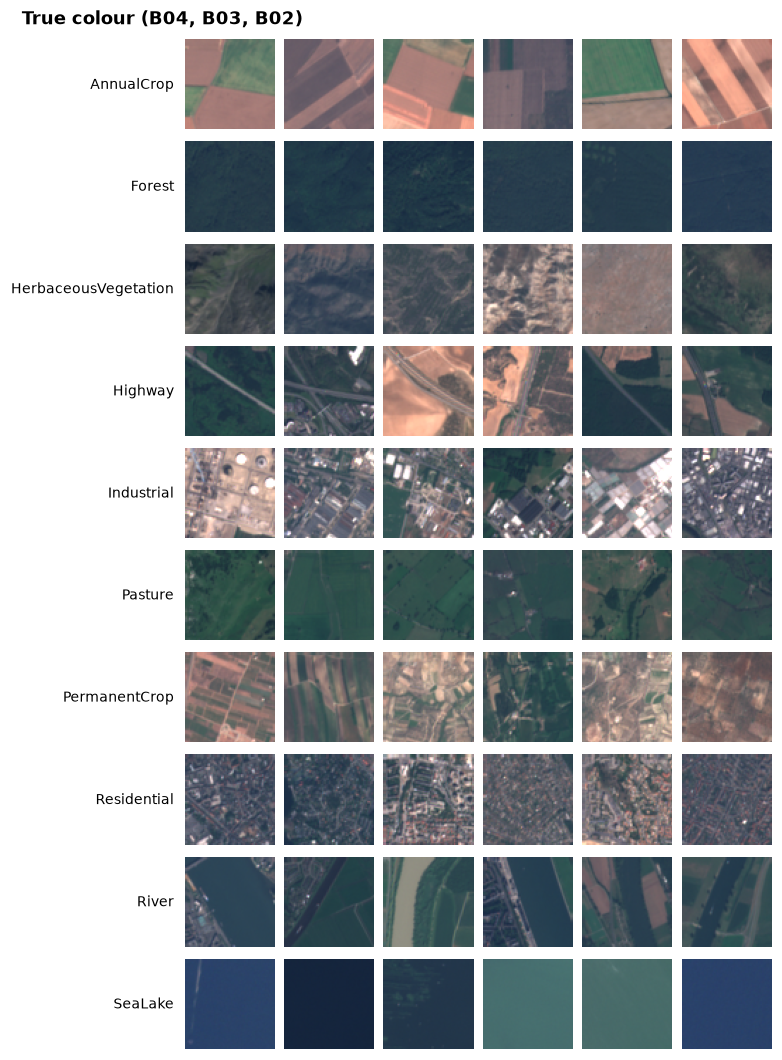

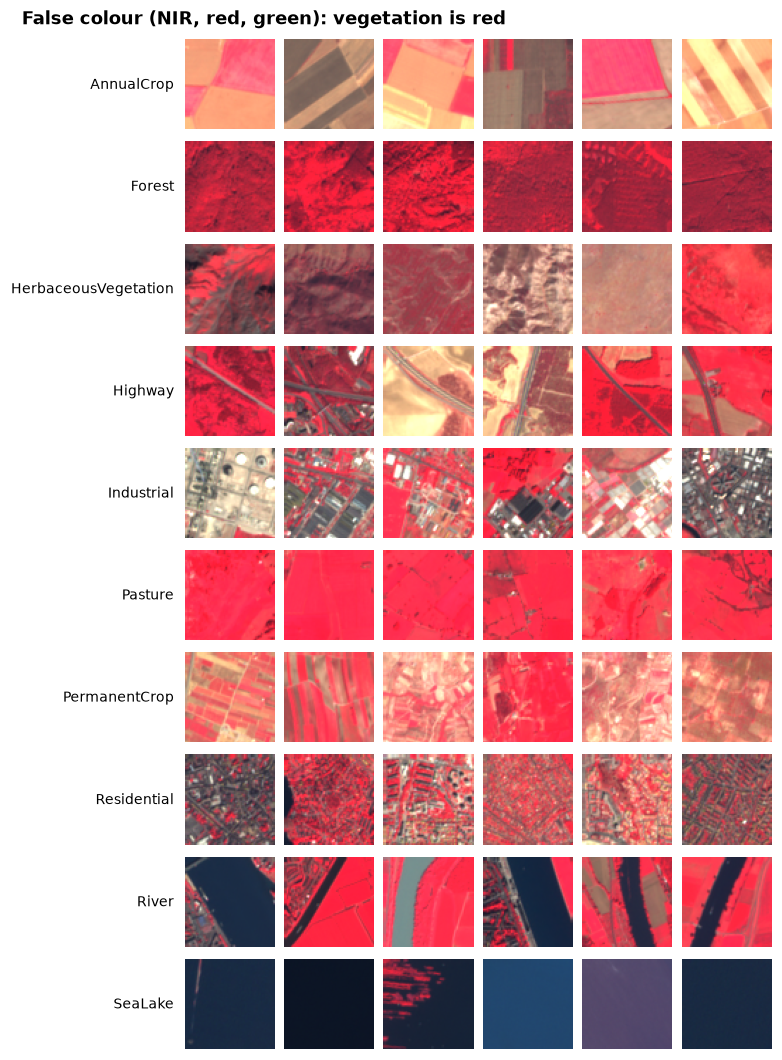

In [3]:
rng = np.random.default_rng(0)
picks = [rng.choice(np.flatnonzero(labels == c), 6, replace=False) for c in range(len(CLASSES))]

def grid(bands, title):
    fig, axes = plt.subplots(len(CLASSES), 6, figsize=(7, 12), layout="compressed")
    for r, rows in enumerate(picks):
        for c, i in enumerate(rows):
            axes[r, c].imshow(composite(arr[i], bands)); axes[r, c].axis("off")
        axes[r, 0].text(-8, 32, CLASSES[r], ha="right", va="center", fontsize=9)
    fig.suptitle(title, x=0.02, ha="left", fontweight="bold")

grid(("B04", "B03", "B02"), "True colour (B04, B03, B02)")
grid(("B08", "B04", "B03"), "False colour (NIR, red, green): vegetation is red")

**→ so what:** at 64×64 px (640 m) the classes are mostly told apart by **texture and layout** (field
patterns, street grids, linear roads and rivers), which is what DINOv2 and a CNN pick up. Highway and River
are thin objects inside mixed patches. AnnualCrop, PermanentCrop and HerbaceousVegetation look alike: expect
confusion between them.

## 3. Value ranges and data quality

In [4]:
sub = arr[::10].astype(np.float32)               # every 10th patch is enough for statistics
pct = np.percentile(sub, [0, 1, 50, 99, 100], axis=(0, 2, 3)).T
q = pd.DataFrame(pct, index=BANDS, columns=["min", "p1", "median", "p99", "max"]).astype(int)
q["description"] = [BAND_DESCRIPTIONS[b] for b in BANDS]
q.loc[list(BANDS_BY_WAVELENGTH)]

,min,p1,median,p99,max,description
B01,820,968,1313,2073,7458,coastal aerosol
B02,116,700,1047,2193,24250,blue
B03,0,454,974,2294,22302,green
B04,1,243,801,2851,26402,red
B05,184,204,1145,2879,20748,red edge 1
B06,157,185,2102,3906,23288,red edge 2
B07,132,166,2465,4880,25268,red edge 3
B08,69,135,2404,4815,28000,NIR
B8A,94,124,2731,5333,27534,narrow NIR
B09,43,57,711,1861,5209,water vapour


In [5]:
import hashlib
flat = arr.reshape(len(arr), len(BANDS), -1)
has_zero = (flat == 0).any(axis=2)
print("patches with any zero pixel:   ", int(has_zero.any(axis=1).sum()), "->", split.loc[has_zero.any(axis=1), "class_name"].value_counts().to_dict())
print("patches with a saturated pixel:", int((flat >= 2**16 - 1).any(axis=(1, 2)).sum()))
print("constant patches (std == 0):   ", int((flat[:, 3].std(axis=1) == 0).sum()))
digests = pd.Series([hashlib.md5(arr[i].tobytes()).hexdigest() for i in range(len(arr))])
print("exact duplicate patches:       ", int(digests.duplicated().sum()))

patches with any zero pixel:    7 -> {'Residential': 7}


patches with a saturated pixel: 0


constant patches (std == 0):    0


exact duplicate patches:        0


**→ so what:** values are reflectance × 10,000. The data is clean: no duplicates, no saturation, and only 7
Residential patches have a few 0-valued pixels (deep shadow), which is harmless. The max is far above p99
(e.g. NIR 28,000 vs 4,800): a few very bright pixels (roofs, clouds). Standardisation is robust enough,
but if training is unstable, **clip at p99** first. Bands live on very different scales
(B10 ≈ 10, NIR ≈ 2,500), so we **standardise per band** using train-split mean/std (already done in
`EuroSATMS`). For RGB images (DINOv2) we use a **fixed** cap (reflectance 0.3), not a per-image stretch,
so Cluj patches are scaled the same way.

## 4. Spectral profile per class

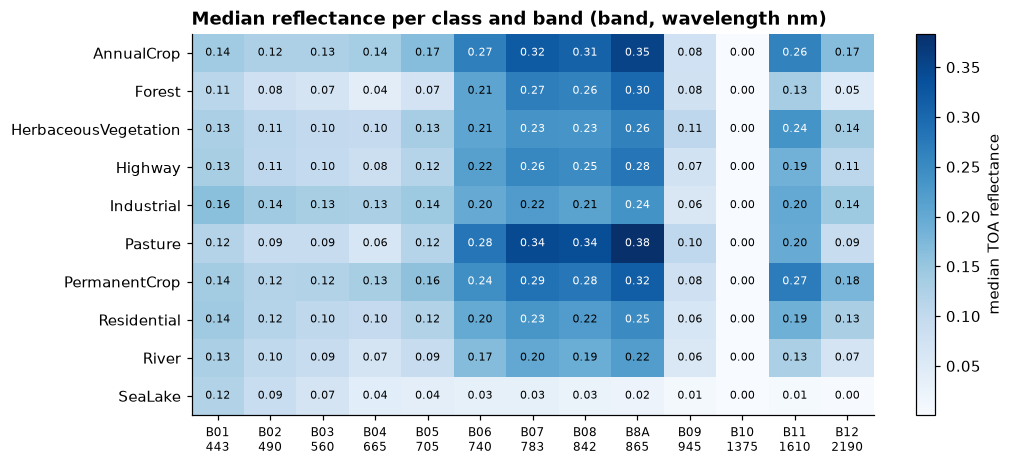

In [6]:
patch_means = np.concatenate([arr[s:s + 3000].mean(axis=(2, 3)) for s in range(0, len(arr), 3000)])  # (27000, 13)
order = [BANDS.index(b) for b in BANDS_BY_WAVELENGTH]
profile = pd.DataFrame([np.median(patch_means[labels == c], axis=0)[order] / 10_000 for c in range(len(CLASSES))],
                       index=CLASSES, columns=BANDS_BY_WAVELENGTH)

fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(profile, cmap="Blues", aspect="auto")
ax.set_xticks(range(13), [f"{b}\n{w}" for b, w in zip(BANDS_BY_WAVELENGTH, sorted(WAVELENGTHS_NM))], fontsize=8)
ax.set_yticks(range(10), CLASSES)
for i in range(10):
    for j in range(13):
        v = profile.iat[i, j]; ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                                       color="white" if v > 0.6 * profile.values.max() else "black")
fig.colorbar(im, label="median TOA reflectance"); ax.set_title("Median reflectance per class and band (band, wavelength nm)")
plt.show()

**→ so what:** the classes differ mostly in **NIR (B06–B8A)** (vegetation is bright, water is dark) and in
**SWIR (B11, B12)** (bare soil and built-up are bright, forest is dark). Visible bands differ less. **B10
(cirrus) is ~0 for every class**: it measures the atmosphere, not the ground.

## 5. Spectral indices

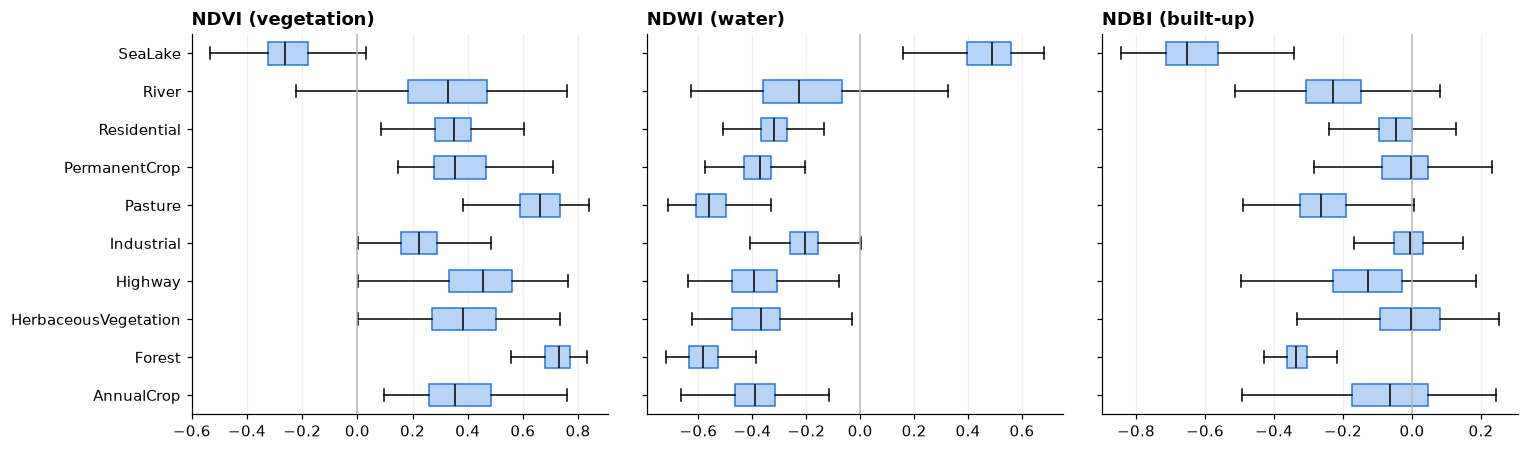

In [7]:
idx_defs = {"NDVI (vegetation)": ("B08", "B04"), "NDWI (water)": ("B03", "B08"), "NDBI (built-up)": ("B11", "B08")}
sample = np.concatenate([rng.choice(np.flatnonzero(labels == c), 500, replace=False) for c in range(10)])
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, (name, (a, b)) in zip(axes, idx_defs.items()):
    vals = np.array([normalized_difference(arr[i], a, b).mean() for i in sample])
    data = [vals[labels[sample] == c] for c in range(10)]
    bp = ax.boxplot(data, orientation="horizontal", showfliers=False, patch_artist=True, widths=0.6,
                    medianprops=dict(color="black"))
    for box in bp["boxes"]: box.set(facecolor=BLUE_LIGHT, edgecolor=BLUE)
    ax.axvline(0, color=GRAY, lw=1); ax.set_title(name); ax.xaxis.grid(True, color="#eee")
axes[0].set_yticks(range(1, 11), CLASSES)
plt.tight_layout(); plt.show()

**→ so what:** NDVI separates forest/pasture from water and industrial, NDWI isolates SeaLake, and NDBI
partly separates built-up classes. The crop and herbaceous classes overlap on all three. These indices are
cheap, explainable features for the **simple baseline**, and NDVI/NDBI changes are a baseline for **change detection**.

## 6. Which bands carry information?
Two quick, model-free checks on the per-patch band means:
* **Fisher score** = between-class variance / within-class variance (higher = the band alone separates classes better).
* **Correlation** between bands (high = redundant).

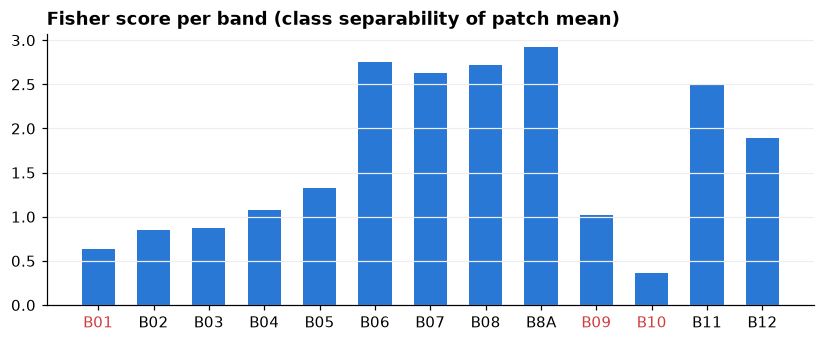

,B01,B02,B03,B04,B05,B06,B07,B08,B8A,B09,B10,B11,B12
B01,1.00,0.95,0.81,0.73,0.63,0.15,0.05,0.03,0.03,-0.04,0.33,0.41,0.55
B02,0.95,1.00,0.94,0.89,0.79,0.26,0.15,0.13,0.12,0.03,0.37,0.57,0.71
B03,0.81,0.94,1.00,0.96,0.92,0.45,0.34,0.32,0.31,0.19,0.42,0.72,0.82
B04,0.73,0.89,0.96,1.00,0.94,0.43,0.31,0.30,0.30,0.20,0.44,0.79,0.88
B05,0.63,0.79,0.92,0.94,1.00,0.67,0.57,0.56,0.56,0.45,0.52,0.90,0.92
B06,0.15,0.26,0.45,0.43,0.67,1.00,0.99,0.99,0.98,0.75,0.39,0.79,0.62
B07,0.05,0.15,0.34,0.31,0.57,0.99,1.00,1.00,1.00,0.74,0.32,0.71,0.52
B08,0.03,0.13,0.32,0.30,0.56,0.99,1.00,1.00,1.00,0.77,0.35,0.71,0.52
B8A,0.03,0.12,0.31,0.30,0.56,0.98,1.00,1.00,1.00,0.74,0.33,0.72,0.52
B09,-0.04,0.03,0.19,0.20,0.45,0.75,0.74,0.77,0.74,1.00,0.57,0.57,0.43


In [8]:
def fisher(x, y):
    mu = x.mean()
    between = sum((y == c).sum() * (x[y == c].mean() - mu) ** 2 for c in np.unique(y))
    within = sum(((x[y == c] - x[y == c].mean()) ** 2).sum() for c in np.unique(y))
    return between / within

scores = pd.Series({b: fisher(patch_means[:, BANDS.index(b)], labels) for b in BANDS_BY_WAVELENGTH})
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(scores.index, scores.values, color=BLUE, width=0.6)
ax.set_title("Fisher score per band (class separability of patch mean)"); ax.yaxis.grid(True, color="#eee")
for tick, b in zip(ax.get_xticklabels(), scores.index):
    if b in ("B01", "B09", "B10"): tick.set_color("#d03b3b")
plt.show()

corr = pd.DataFrame(np.corrcoef(patch_means[:, order].T), index=BANDS_BY_WAVELENGTH, columns=BANDS_BY_WAVELENGTH)
corr.style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1).format("{:.2f}")

**→ so what:**
* **NIR / red edge (B06–B8A) and SWIR 1 (B11)** separate classes best (Fisher ≈ 2.5–2.9), then SWIR 2 (B12).
  The visible bands are weaker on their own (≈ 0.9–1.1) but carry the spatial detail that the image models use.
* **B10 (cirrus) and B01 (aerosol)** are the least informative. **B09 (water vapour)** scores about as well as the
  visible bands on EuroSAT, but all three are 60 m *atmospheric* bands (blurry, see
  `figures/eurosat/04_bands_per_class.png`): what they measure depends on the air on the day of capture, and they
  are what L1C→L2A atmospheric correction changes most. So they are the ones least likely to transfer to Cluj.
* **B06, B07, B08 and B8A are almost perfectly correlated** (r ≈ 0.99–1.00) and so are B02/B03/B04 among
  themselves. Keeping all of them adds little information, but it costs little for a CNN.
* The most useful groups are **visible (B02–B04)**, **red edge/NIR (B05–B8A)** and **SWIR (B11–B12)**.

## 7. Summary: which channels to use

| Model | Channels | Why |
|---|---|---|
| **DINOv2-S + linear** (main) | **B04, B03, B02** (RGB) | DINOv2 was pretrained on RGB photos. Optional ablation: NIR-R-G false colour. |
| **Simple baseline** | per-band mean + std of the **10 surface bands**, plus NDVI, NDWI, NDBI | cheap, interpretable |
| **Small CNN** (main) | **10 surface bands**: B02, B03, B04, B05, B06, B07, B08, B8A, B11, B12 | drop the 60 m atmospheric bands (B01, B09, B10): they carry little land-cover signal and are what atmospheric correction changes most, so they transfer worst from L1C (EuroSAT) to L2A (Cluj) |
| CNN ablation | 12 bands (`L2A_BANDS`, everything except B10) | shows whether B01/B09 help on EuroSAT and hurt on Cluj |
| CNN ablation (EuroSAT only) | all 13 bands | upper bound on EuroSAT; **cannot** run on Cluj L2A (no B10) |

The rule: **every channel must exist, with the same meaning, in the Cluj L2A imagery.** That rules out B10 completely.